# GameFormer, from observations to joint futures

Reimplement the released WOMD joint predictor in plain PyTorch. Level-k means each stage responds to the previous stage’s predicted futures. The code below defines the complete model locally, component by component. Planning uses the same architecture with a different objective.

Sources: [paper](https://arxiv.org/abs/2303.05760), [supplement](https://openaccess.thecvf.com/content/ICCV2023/supplemental/Huang_GameFormer_Game-theoretic_Modeling_ICCV_2023_supplemental.pdf), [pinned release](https://github.com/MCZhi/GameFormer/tree/fcb0d4a0f5cbbcecf69f9b9796366d6f5f2ce128). The paper uses K6; the released trainer defaults to K3. Synthetic execution does not reproduce paper results. This notebook uses a smaller named CPU recipe.

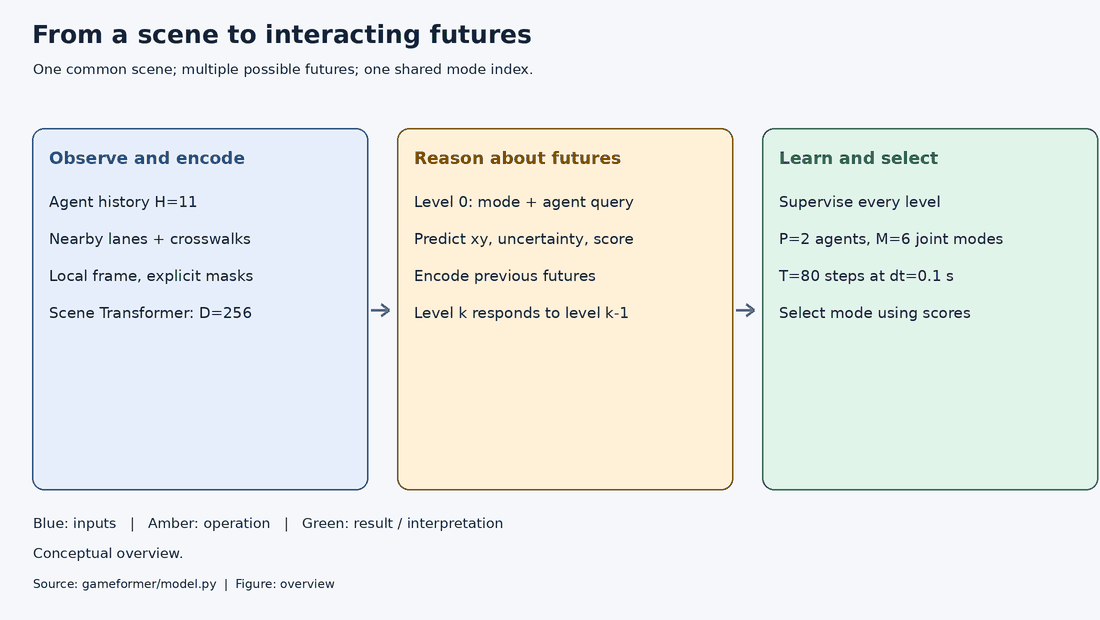

*One common scene; multiple possible futures; one shared mode index.*

## Setup

Requires Python >=3.11, PyTorch, NumPy and Matplotlib. Default execution is seeded, offline, on CPU. The full release uses D256, E6, K3, C34, P2, M6, H11 and T80. We retain T80 for the actual objective but reduce width, depth and context for the probes.

In [ ]:
import math
from dataclasses import dataclass
from typing import cast

import matplotlib.pyplot as plt
import torch
from torch import Tensor, nn
from torch.nn import functional as F

torch.set_num_threads(1)
torch.manual_seed(3407)
print("CPU:", torch.__version__)

In [ ]:
@dataclass(frozen=True)
class ModelConfig:
    width: int = 256
    heads: int = 8
    encoder_layers: int = 6
    levels: int = 3
    modes: int = 6
    actors: int = 34
    predicted: int = 2
    history: int = 11
    future: int = 80
    lanes: int = 6
    lane_points: int = 100
    crosswalks: int = 4
    crosswalk_points: int = 50
    lane_stride: int = 10
    crosswalk_stride: int = 10
    dropout: float = 0.1
    partial_segments: bool = False
    legacy_lane_columns: bool = True
    legacy_heading: bool = True
    normalized_future_pool: bool = False

    def __post_init__(self) -> None:
        integers = (
            self.width,
            self.heads,
            self.encoder_layers,
            self.modes,
            self.actors,
            self.predicted,
            self.history,
            self.future,
            self.lanes,
            self.lane_points,
            self.crosswalks,
            self.crosswalk_points,
            self.lane_stride,
            self.crosswalk_stride,
        )
        if any(x < 1 for x in integers) or self.levels < 0:
            raise ValueError("Model dimensions must be positive; levels may be zero")
        if self.width % self.heads or self.width % 2 or self.predicted > self.actors:
            raise ValueError("Width must be even/divisible by heads; predicted <= actors")
        if self.lane_points % self.lane_stride or self.crosswalk_points % self.crosswalk_stride:
            raise ValueError("Map point counts must be divisible by segment strides")
        if not 0 <= self.dropout < 1:
            raise ValueError("Dropout must be in [0,1)")

    @classmethod
    def smoke(cls) -> "ModelConfig":
        return cls(
            width=32,
            heads=4,
            encoder_layers=1,
            levels=1,
            actors=4,
            lanes=2,
            lane_points=20,
            crosswalks=1,
            crosswalk_points=10,
            dropout=0,
        )

## Data, coordinates and explicit masks

$p_{local}=R(-\theta_0)(p_{world}-p_0)$; positions are meters and angles radians. The first target defines the origin and need not be the autonomous vehicle. `actor_valid`, `lane_valid`, `crosswalk_valid` and `future_valid` distinguish missing data from legitimate zero coordinates. Future labels are excluded from model inputs. A scene contains observations [C,H,9], lane points [P,L,Q,17], crosswalks [P,W,R,3] and targets [P,T,2].

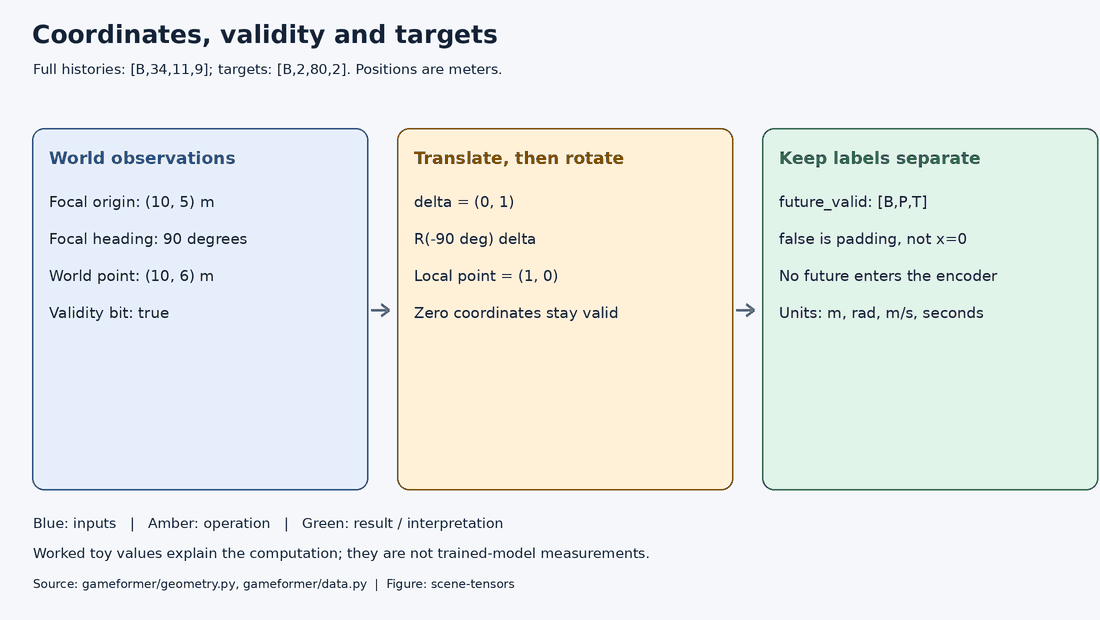

*Full histories: [B,34,11,9]; targets: [B,2,80,2]. Positions are meters.*

In [ ]:
def world_to_local(xy: Tensor, origin: Tensor, heading: Tensor) -> Tensor:
    while origin.ndim < xy.ndim:
        origin = origin.unsqueeze(-2)
    while heading.ndim < xy.ndim - 1:
        heading = heading.unsqueeze(-1)
    delta = xy - origin
    c, s = heading.cos(), heading.sin()
    return torch.stack(
        (c * delta[..., 0] + s * delta[..., 1], -s * delta[..., 0] + c * delta[..., 1]), -1
    )


def local_to_world(xy: Tensor, origin: Tensor, heading: Tensor) -> Tensor:
    while origin.ndim < xy.ndim:
        origin = origin.unsqueeze(-2)
    return world_to_local(xy, torch.zeros_like(origin), -heading) + origin


def wrap_angle(angle: Tensor) -> Tensor:
    return torch.atan2(angle.sin(), angle.cos())


def shapes(c: ModelConfig) -> dict[str, tuple[int, ...]]:
    return {
        "ego_state": (c.history, 9),
        "neighbors_state": (c.actors - 1, c.history, 9),
        "actor_valid": (c.actors, c.history),
        "map_lanes": (c.predicted, c.lanes, c.lane_points, 17),
        "lane_valid": (c.predicted, c.lanes, c.lane_points),
        "map_crosswalks": (c.predicted, c.crosswalks, c.crosswalk_points, 3),
        "crosswalk_valid": (c.predicted, c.crosswalks, c.crosswalk_points),
        "future": (c.predicted, c.future, 2),
        "future_state": (c.predicted, c.future, 5),
        "future_valid": (c.predicted, c.future),
    }


def validate_sample(sample: dict[str, Tensor], config: ModelConfig) -> None:
    for name, shape in shapes(config).items():
        if name not in sample or tuple(sample[name].shape) != shape:
            raise ValueError(f"{name}: expected {shape}; explicit masks and future_state required")
        if name.endswith("valid") and sample[name].dtype != torch.bool:
            raise ValueError(f"{name} must be boolean")
    actors = torch.cat((sample["ego_state"][None], sample["neighbors_state"]))
    for values, valid in (
        (actors, sample["actor_valid"]),
        (sample["map_lanes"], sample["lane_valid"]),
        (sample["map_crosswalks"], sample["crosswalk_valid"]),
        (sample["future_state"], sample["future_valid"]),
        (sample["future"], sample["future_valid"]),
    ):
        if not torch.isfinite(values[valid]).all():
            raise ValueError("Non-finite value in a valid scene entry")
    if not sample["actor_valid"][0, -1]:
        raise ValueError("Focal actor must be valid at the current time")
    ids = actors[..., 8][sample["actor_valid"]]
    if ((ids < 0) | (ids > 3) | (ids != ids.round())).any():
        raise ValueError("Agent type IDs must be integers in [0,3]")


def synthetic_sample(c: ModelConfig, index: int, seed: int = 3407) -> dict[str, Tensor]:
    """Illustrative constant-velocity scenes; this is not a WOMD sample."""
    g = torch.Generator().manual_seed(seed + index)
    actors = torch.zeros(c.actors, c.history, 9)
    positions = torch.randn(c.actors, 2, generator=g) * 4
    positions[0] = 0
    velocity = torch.randn(c.actors, 2, generator=g) * 0.2
    velocity[:, 0] += 2
    times = torch.arange(1 - c.history, 1) * 0.1
    actors[..., :2] = positions[:, None] + velocity[:, None] * times[None, :, None]
    actors[..., 2] = torch.atan2(velocity[:, 1], velocity[:, 0])[:, None]
    actors[..., 3:5] = velocity[:, None]
    actors[..., 5:8] = torch.tensor([4.0, 2.0, 1.5])
    actors[..., 8] = torch.arange(c.actors).remainder(3)[:, None] + 1
    lanes = torch.zeros(c.predicted, c.lanes, c.lane_points, 17)
    x = torch.linspace(-5, 40, c.lane_points)
    for lane in range(c.lanes):
        for offset, y in ((0, lane * 3.0), (3, lane * 3.0 + 1.5), (6, lane * 3.0 - 1.5)):
            lanes[:, lane, :, offset] = x
            lanes[:, lane, :, offset + 1] = y
    lanes[..., 9] = 13.4
    lanes[..., 10:13] = 1
    crosswalks = torch.randn(c.predicted, c.crosswalks, c.crosswalk_points, 3, generator=g)
    future_times = torch.arange(1, c.future + 1) * 0.1
    future = (
        positions[: c.predicted, None] + velocity[: c.predicted, None] * future_times[None, :, None]
    )
    state = torch.cat((future, actors[: c.predicted, -1, None, 2:5].expand(-1, c.future, -1)), -1)
    sample = {
        "ego_state": actors[0],
        "neighbors_state": actors[1:],
        "actor_valid": torch.ones(c.actors, c.history, dtype=torch.bool),
        "map_lanes": lanes,
        "lane_valid": torch.ones(lanes.shape[:-1], dtype=torch.bool),
        "map_crosswalks": crosswalks,
        "crosswalk_valid": torch.ones(crosswalks.shape[:-1], dtype=torch.bool),
        "future": future,
        "future_state": state,
        "future_valid": torch.ones(c.predicted, c.future, dtype=torch.bool),
    }
    validate_sample(sample, c)
    return sample

In [ ]:
config = ModelConfig.smoke()
samples = [synthetic_sample(config, i, 3407) for i in range(2)]
batch = {key: torch.stack([s[key] for s in samples]) for key in samples[0]}
assert batch["actor_valid"][0, 0, -1]
assert torch.equal(batch["ego_state"][0, -1, :2], torch.zeros(2))
print({key: tuple(value.shape) for key, value in batch.items()})

## Actor history

An LSTM updates memory as $c_t=f_t c_{t-1}+i_t g_t$ and $h_t=o_t\tanh(c_t)$. Two layers encode eight numeric fields; the last hidden state receives a categorical type embedding. Separate weights encode the focal actor and all remaining actors. Invalid history rows are zeroed before encoding; the current validity controls the actor attention mask.

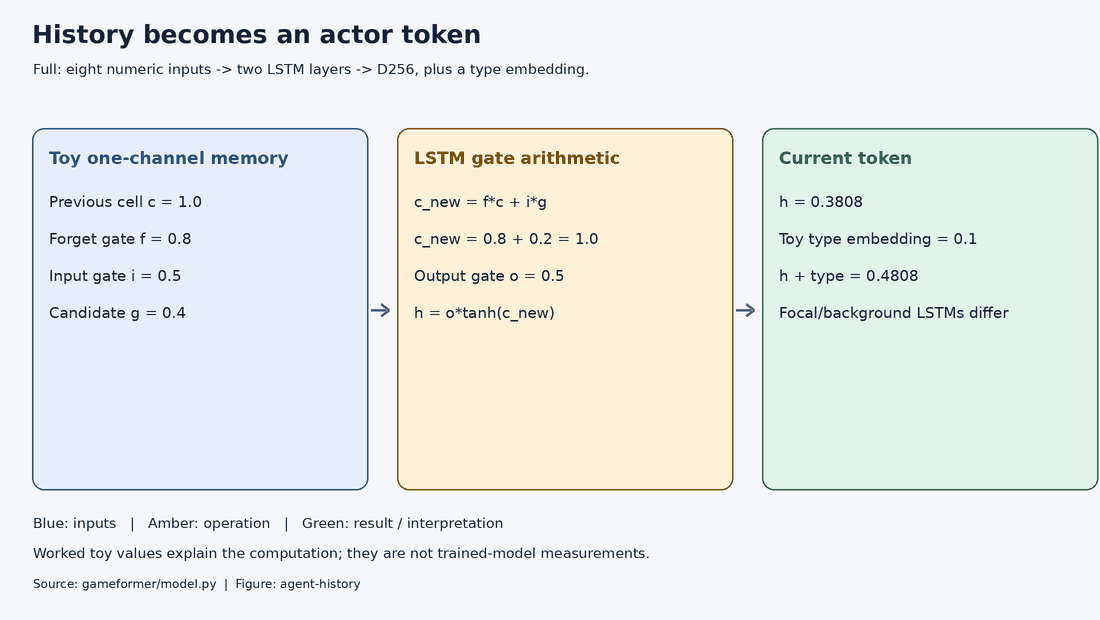

*Full: eight numeric inputs -> two LSTM layers -> D256, plus a type embedding.*

In [ ]:
class AgentEncoder(nn.Module):
    def __init__(self, width: int):
        super().__init__()
        self.motion = nn.LSTM(8, width, 2, batch_first=True)
        self.type_emb = nn.Embedding(4, width, padding_idx=0)

    def forward(self, states: Tensor) -> Tensor:
        encoded, _ = self.motion(states[..., :8])
        return encoded[:, -1] + self.type_emb(states[:, -1, 8].long())

In [ ]:
actor_encoder = AgentEncoder(config.width)
assert actor_encoder(batch["ego_state"]).shape == (2, config.width)

## Lane points

Numeric boundary coordinates use linear projections; discrete IDs use embeddings. Concatenate three 128-channel geometry features, 64 speed channels and 64 summed semantic channels; apply a 512→384→D MLP, then sinusoidal point positions $PE_{p,2j}=\sin(p/10000^{2j/D})$. The source has a lane-column disagreement: compatibility uses 14/15, whereas corrected semantics use 15/16. The configuration names this choice.

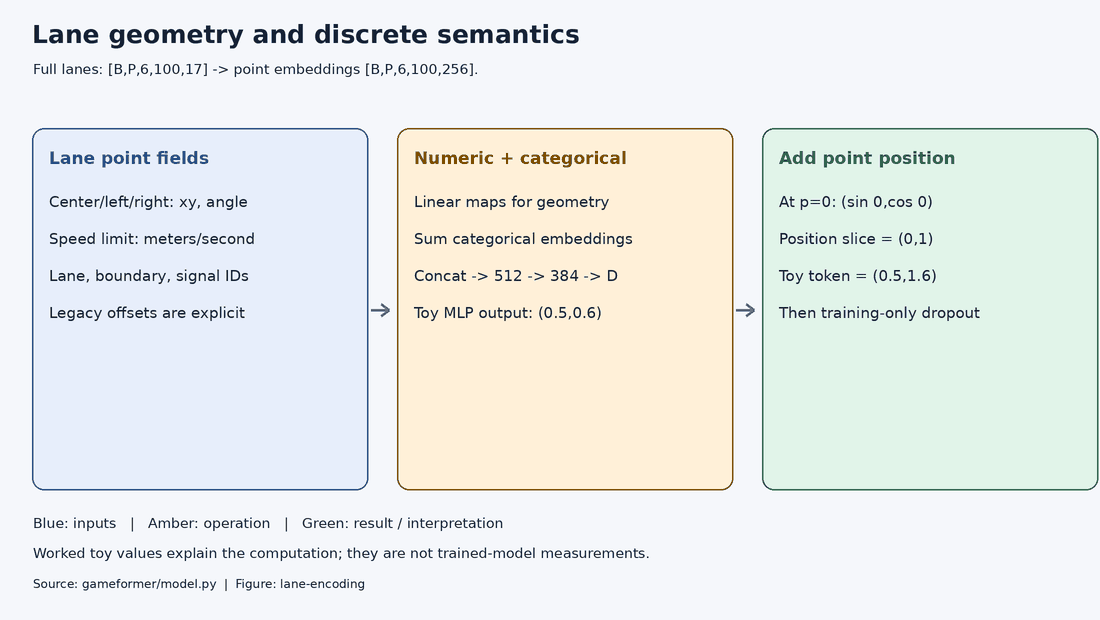

*Full lanes: [B,P,6,100,17] -> point embeddings [B,P,6,100,256].*

In [ ]:
class PositionalEncoding(nn.Module):
    pe: Tensor

    def __init__(self, width: int, length: int, dropout: float):
        super().__init__()
        positions = torch.arange(length)[:, None]
        divisor = torch.exp(torch.arange(0, width, 2) * (-math.log(10000.0) / width))
        pe = torch.zeros(length, width)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(positions * divisor), torch.cos(positions * divisor)
        self.register_buffer("pe", pe)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: Tensor) -> Tensor:
        return self.dropout(x + self.pe)


class LaneEncoder(nn.Module):
    def __init__(self, c: ModelConfig):
        super().__init__()
        self.lines = nn.ModuleList([nn.Linear(3, 128) for _ in range(3)])
        self.speed = nn.Linear(1, 64)
        self.attributes = nn.ModuleList(
            [
                nn.Embedding(n, 64, padding_idx=0 if i < 4 else None)
                for i, n in enumerate((4, 11, 11, 9, 2, 2))
            ]
        )
        self.pointnet = nn.Sequential(nn.Linear(512, 384), nn.ReLU(), nn.Linear(384, c.width))
        self.position = PositionalEncoding(c.width, c.lane_points, c.dropout)
        self.columns = (
            (10, 11, 12, 13, 14, 15) if c.legacy_lane_columns else (10, 11, 12, 13, 15, 16)
        )

    def forward(self, lanes: Tensor) -> Tensor:
        numeric = [layer(lanes[..., i * 3 : i * 3 + 3]) for i, layer in enumerate(self.lines)]
        semantic = sum(
            layer(lanes[..., col].long())
            for col, layer in zip(self.columns, self.attributes, strict=True)
        )
        return self.position(
            self.pointnet(torch.cat([*numeric, self.speed(lanes[..., 9:10]), semantic], -1))
        )

In [ ]:
lane_encoder = LaneEncoder(config)
assert lane_encoder(batch["map_lanes"]).shape[-1] == config.width

## Crosswalk points

A local MLP maps three numeric fields (x,y,heading) through 64, 128 and D channels with ReLU activations. It preserves every point until pooling. No external map encoder or model library is used.

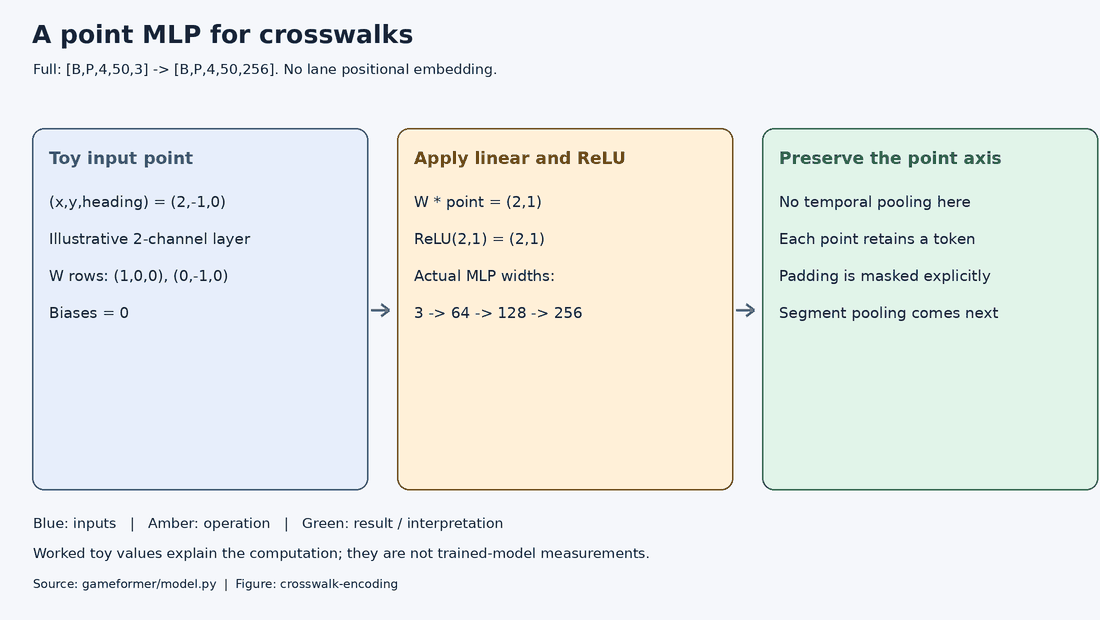

*Full: [B,P,4,50,3] -> [B,P,4,50,256]. No lane positional embedding.*

In [ ]:
class CrosswalkEncoder(nn.Module):
    def __init__(self, width: int):
        super().__init__()
        self.pointnet = nn.Sequential(
            nn.Linear(3, 64), nn.ReLU(), nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, width)
        )

    def forward(self, points: Tensor) -> Tensor:
        return self.pointnet(points)

In [ ]:
crosswalk_encoder = CrosswalkEncoder(config.width)
assert crosswalk_encoder(batch["map_crosswalks"]).shape[-1] == config.width

## Reduce map tokens

$z_{segment,d}=\max_{q\in valid} z_{q,d}$. Different channels can select different points. Every pooled token retains a padding flag (True means hidden). The released policy hides a partly invalid segment; the practical policy admits any valid point. Entirely empty groups produce zero features and remain hidden.

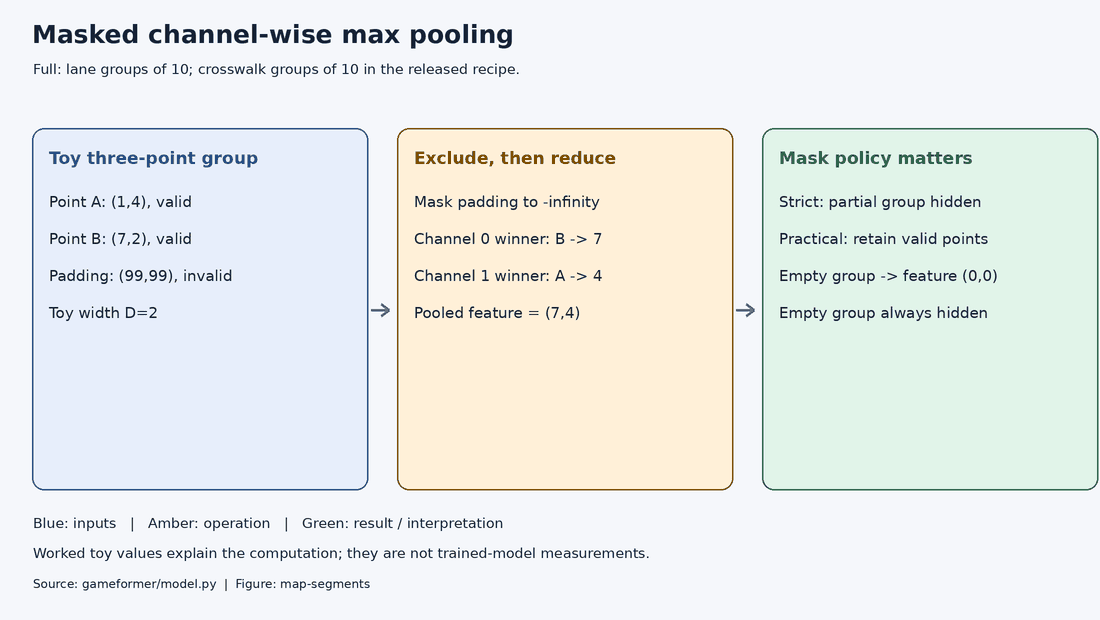

*Full: lane groups of 10; crosswalk groups of 10 in the released recipe.*

In [ ]:
def segment_points(
    features: Tensor, valid: Tensor, stride: int, partial: bool = False
) -> tuple[Tensor, Tensor]:
    """[B,L,Q,D] -> [B,L*Q/stride,D], True padding mask; never pool padding."""
    b, lanes, points, width = features.shape
    grouped = features.reshape(b, lanes, points // stride, stride, width)
    flags = valid.reshape(b, lanes, points // stride, stride)
    pooled = grouped.masked_fill(~flags[..., None], -torch.inf).amax(-2)
    any_valid = flags.any(-1)
    pooled = torch.where(any_valid[..., None], pooled, 0)
    usable = any_valid if partial else flags.all(-1)
    return pooled.reshape(b, -1, width), ~usable.reshape(b, -1)

In [ ]:
toy = torch.tensor([[[[1.0, 4.0], [7.0, 2.0], [99.0, 99.0]]]])
pooled, padding = segment_points(toy, torch.tensor([[[True, True, False]]]), 3, True)
torch.testing.assert_close(pooled, torch.tensor([[[7.0, 4.0]]]))
assert not padding.any()

## Context and attention

$Attention(Q,K,V)=softmax(QK^T/\sqrt{d}+mask)V$. Concatenate actor tokens and the target agent’s local map. The scene Transformer uses post-normalization and residual connections. The released cross-attention block normalizes the read without adding the query, an important implementation detail. FFN means a two-layer feature network.

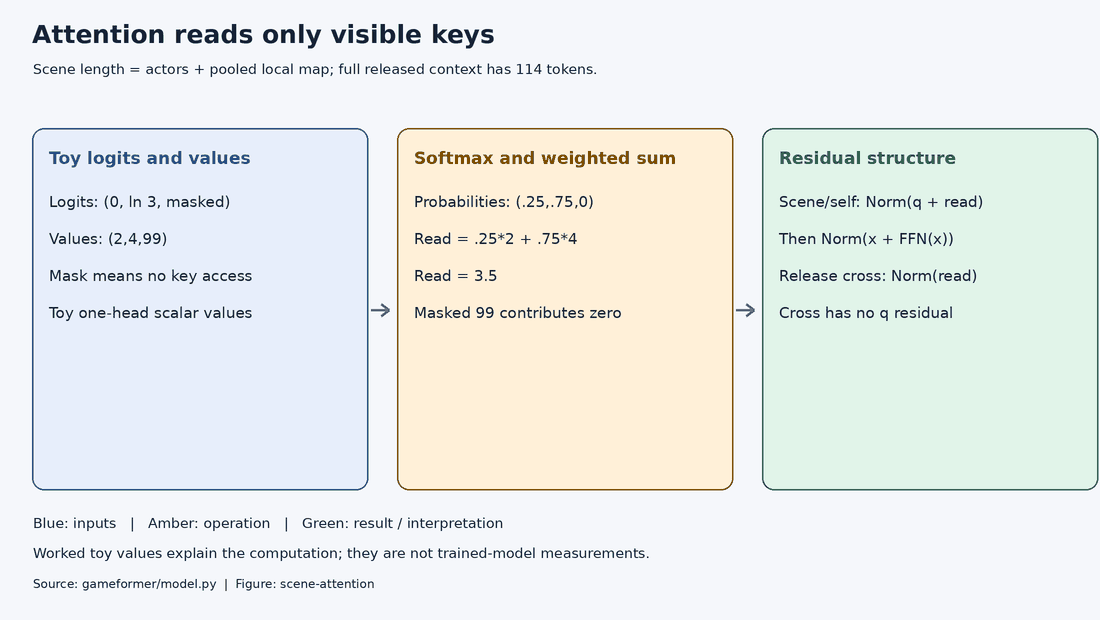

*Scene length = actors + pooled local map; full released context has 114 tokens.*

In [ ]:
class AttentionBlock(nn.Module):
    """Post-norm attention. Cross-attention has no query residual in the release."""

    def __init__(self, c: ModelConfig, self_attention: bool = False):
        super().__init__()
        self.attention = nn.MultiheadAttention(c.width, c.heads, c.dropout, batch_first=True)
        self.norm1, self.norm2 = nn.LayerNorm(c.width), nn.LayerNorm(c.width)
        self.ffn = nn.Sequential(
            nn.Linear(c.width, c.width * 4),
            nn.GELU(),
            nn.Dropout(c.dropout),
            nn.Linear(c.width * 4, c.width),
            nn.Dropout(c.dropout),
        )
        self.self_attention = self_attention

    def forward(self, query: Tensor, context: Tensor, mask: Tensor) -> Tensor:
        attended = self.attention(
            query, context, context, key_padding_mask=mask, need_weights=False
        )[0]
        attended = self.norm1(attended + query if self.self_attention else attended)
        return self.norm2(attended + self.ffn(attended))

In [ ]:
attention = AttentionBlock(config, self_attention=True)
tokens = torch.randn(2, 3, config.width)
assert attention(tokens, tokens, torch.zeros(2, 3, dtype=torch.bool)).shape == tokens.shape

## Level-0 queries

$q_{i,m}=context_i+embedding_{agent,i}+embedding_{mode,m}$. Each agent and mode gets a distinct query, which reads the common scene through cross-attention. No previous future is available at this stage.

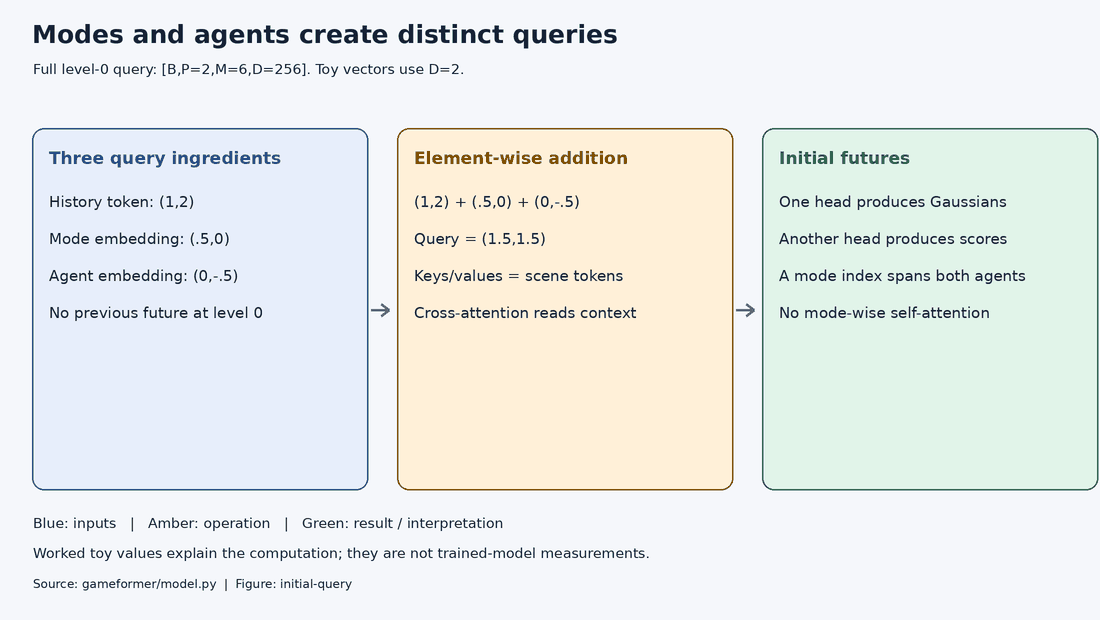

*Full level-0 query: [B,P=2,M=6,D=256]. Toy vectors use D=2.*

In [ ]:
query = torch.tensor([1.0, 2.0]) + torch.tensor([0.5, 0.0]) + torch.tensor([0.0, -0.5])
torch.testing.assert_close(query, torch.tensor([1.5, 1.5]))

## Decode Gaussian components

A Gaussian mixture represents alternative possible futures. Each mode has a mean (x,y), diagonal log standard deviations, and a score. The head emits offsets from the current position, rather than per-step increments. $\mu_t=p_{current}+\Delta p_t$ and $\sigma_t=\exp(log\sigma_t)$.

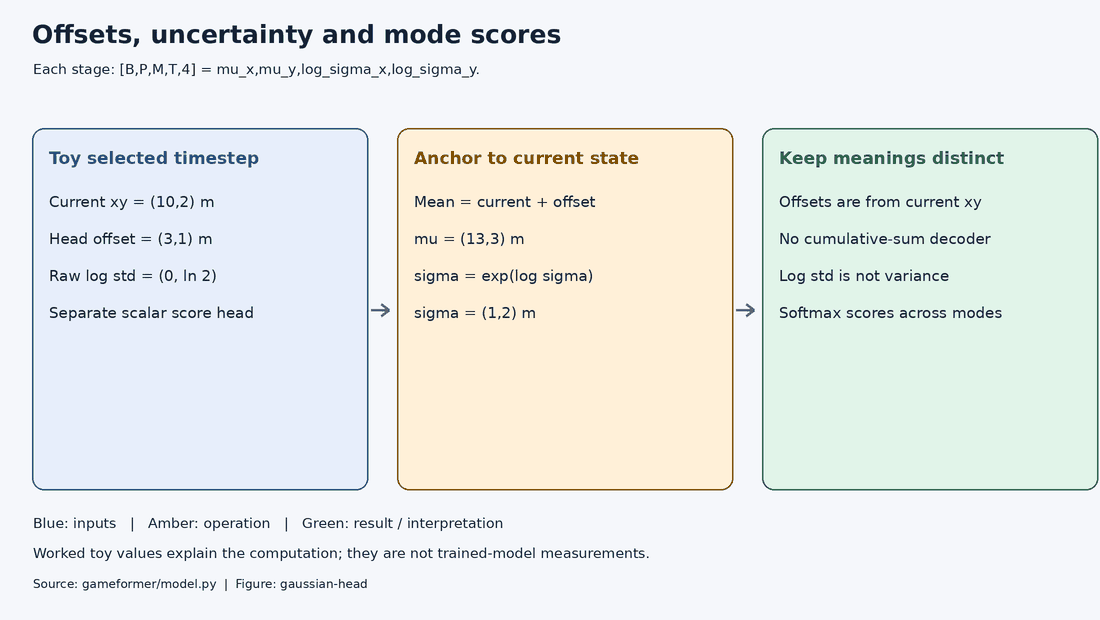

*Each stage: [B,P,M,T,4] = mu_x,mu_y,log_sigma_x,log_sigma_y.*

In [ ]:
class GaussianHead(nn.Module):
    def __init__(self, c: ModelConfig):
        super().__init__()
        self.future = c.future
        self.gaussian = nn.Sequential(
            nn.Linear(c.width, c.width * 2),
            nn.ELU(),
            nn.Dropout(c.dropout),
            nn.Linear(c.width * 2, c.future * 4),
        )
        self.score = nn.Sequential(
            nn.Linear(c.width, 64), nn.ELU(), nn.Dropout(c.dropout), nn.Linear(64, 1)
        )

    def forward(self, content: Tensor, current: Tensor) -> tuple[Tensor, Tensor]:
        raw = self.gaussian(content).reshape(*content.shape[:-1], self.future, 4)
        result = torch.cat((raw[..., :2] + current[:, :, None, None, :2], raw[..., 2:]), -1)
        return result, self.score(content).squeeze(-1)

In [ ]:
head = GaussianHead(config)
means, scores = head(torch.randn(2, 2, 6, config.width), torch.zeros(2, 2, 9))
assert means.shape == (2, 2, 6, 80, 4) and scores.shape == (2, 2, 6)

## Future kinematics and a gradient barrier

$v_t=(p_t-p_{t-1})/0.1$. Append heading and box dimensions to form eight channels. A shared MLP and time maximum encode every candidate future. The input kinematics are detached: this path cannot change previous xy through backpropagation. The future MLP, prior query content and score paths still learn. The legacy positive-dx clamp is explicit in configuration.

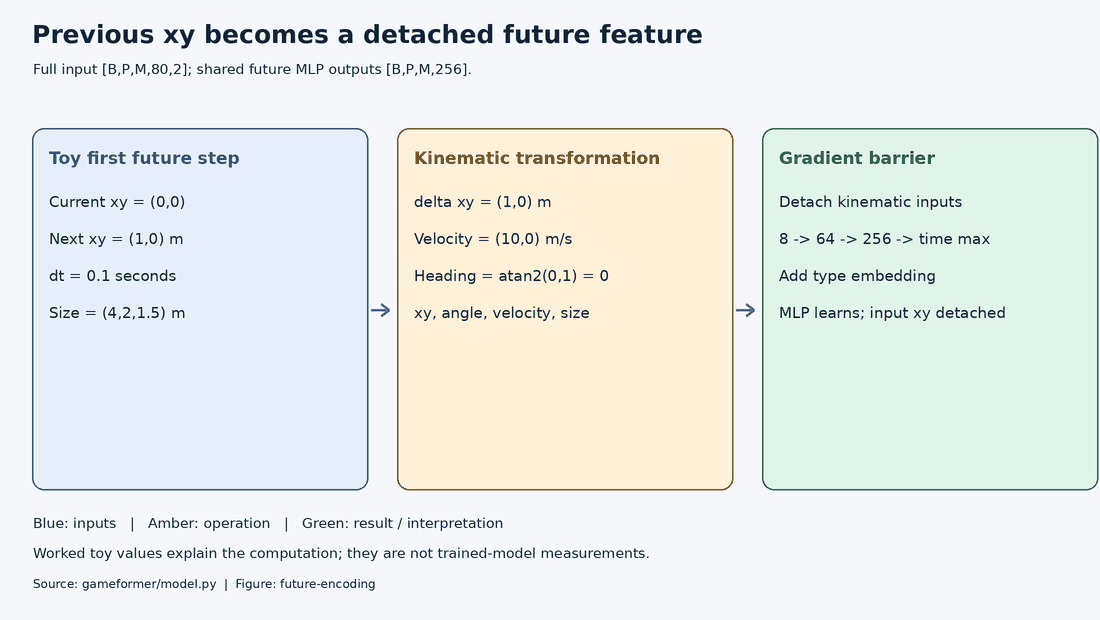

*Full input [B,P,M,80,2]; shared future MLP outputs [B,P,M,256].*

In [ ]:
class FutureEncoder(nn.Module):
    def __init__(self, c: ModelConfig):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(8, 64), nn.ReLU(), nn.Linear(64, c.width))
        self.type_emb = nn.Embedding(4, c.width, padding_idx=0)
        self.legacy_heading = c.legacy_heading

    def forward(self, trajectories: Tensor, current: Tensor) -> Tensor:
        # B,P,M,T,2; append the observed current xy before finite differences.
        start = current[:, :, None, None, :2].expand(-1, -1, trajectories.shape[2], -1, -1)
        delta = torch.diff(torch.cat((start, trajectories), -2), dim=-2)
        dx = delta[..., 0].clamp_min(1e-3) if self.legacy_heading else delta[..., 0]
        angle = torch.atan2(delta[..., 1], dx)[..., None]
        size = current[:, :, None, None, 5:8].expand(*trajectories.shape[:-1], 3)
        states = torch.cat((trajectories, angle, delta / 0.1, size), -1)
        features = self.mlp(states.detach()).amax(-2)
        return features + self.type_emb(current[:, :, None, 8].long())

In [ ]:
future_encoder = FutureEncoder(config)
xy = torch.randn(2, 2, 6, 80, 2, requires_grad=True)
encoded = future_encoder(xy, torch.zeros(2, 2, 9))
encoded.sum().backward()
assert xy.grad is None
assert future_encoder.mlp[0].weight.grad is not None

## Probability pooling and future interaction

The release computes $f_i=\frac1M\sum_m softmax(s_i)_m e_{i,m}$. This has an additional 1/M compared with a normalized expectation. Preserve it for compatibility. Self-attention mixes agents’ future tokens; each interaction level owns its attention and Gaussian head, while the future-feature MLP is shared across levels.

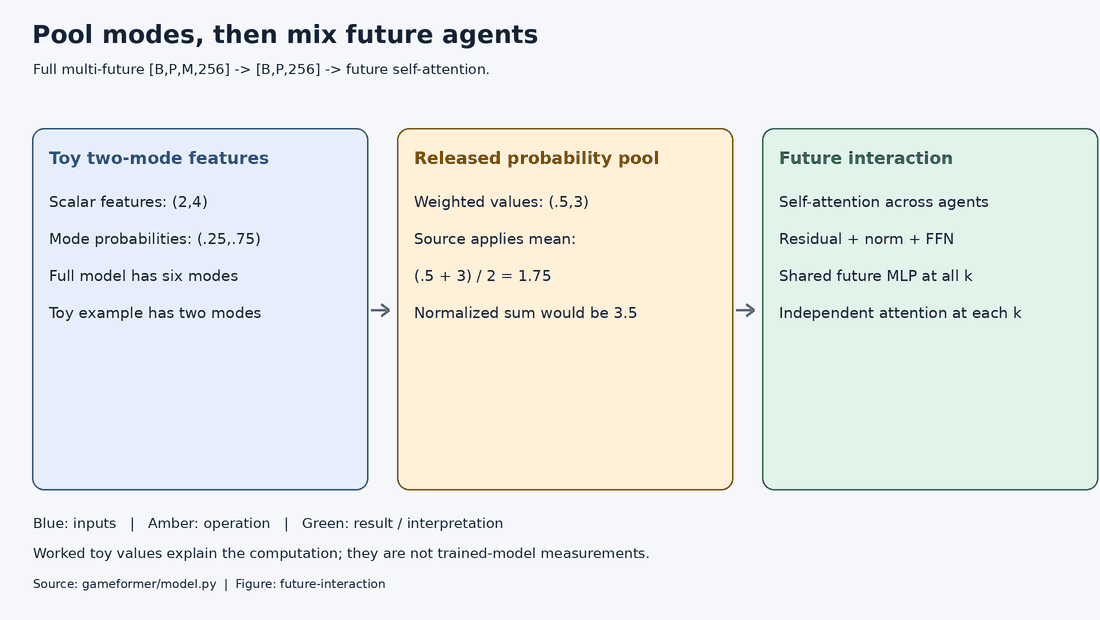

*Full multi-future [B,P,M,256] -> [B,P,256] -> future self-attention.*

In [ ]:
class InteractionDecoder(nn.Module):
    def __init__(self, c: ModelConfig):
        super().__init__()
        self.interaction = AttentionBlock(c, self_attention=True)
        self.cross = AttentionBlock(c)
        self.head = GaussianHead(c)

In [ ]:
toy_pool = (torch.tensor([2.0, 4.0]) * torch.tensor([0.25, 0.75])).mean()
assert toy_pool.item() == 1.75
interaction = InteractionDecoder(config)

## Level-k cross-attention

Append mixed future tokens to the original scene. Add the own multi-future embedding to prior query content, then read this extended context. Hide the own-future key after future self-attention, matching the release. This masking location does not establish complete causal isolation.

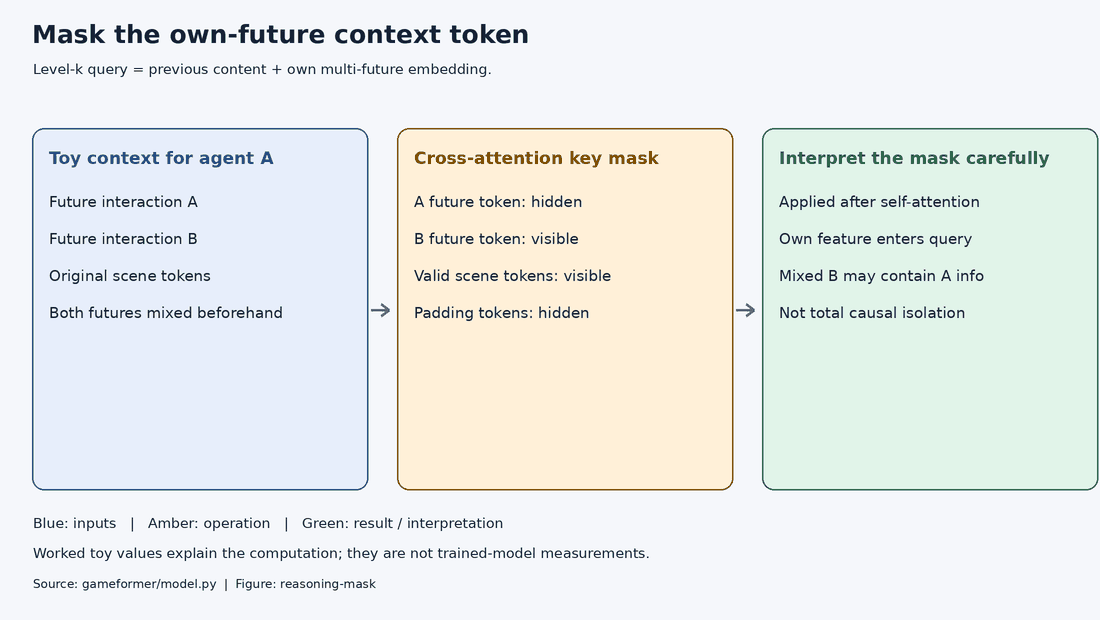

*Level-k query = previous content + own multi-future embedding.*

In [ ]:
own_future_hidden = torch.eye(config.predicted, dtype=torch.bool)
assert own_future_hidden.tolist() == [[True, False], [False, True]]

## Assemble the complete model

All observed actors appear in every agent-local context. Only the first P actors are decoded. For each level, predicted means and scores feed the next level, alongside previous query content. Retain all K+1 stages for deep supervision. Vectorized agent contexts match release operations in evaluation; training dropout draws need not follow upstream RNG order.

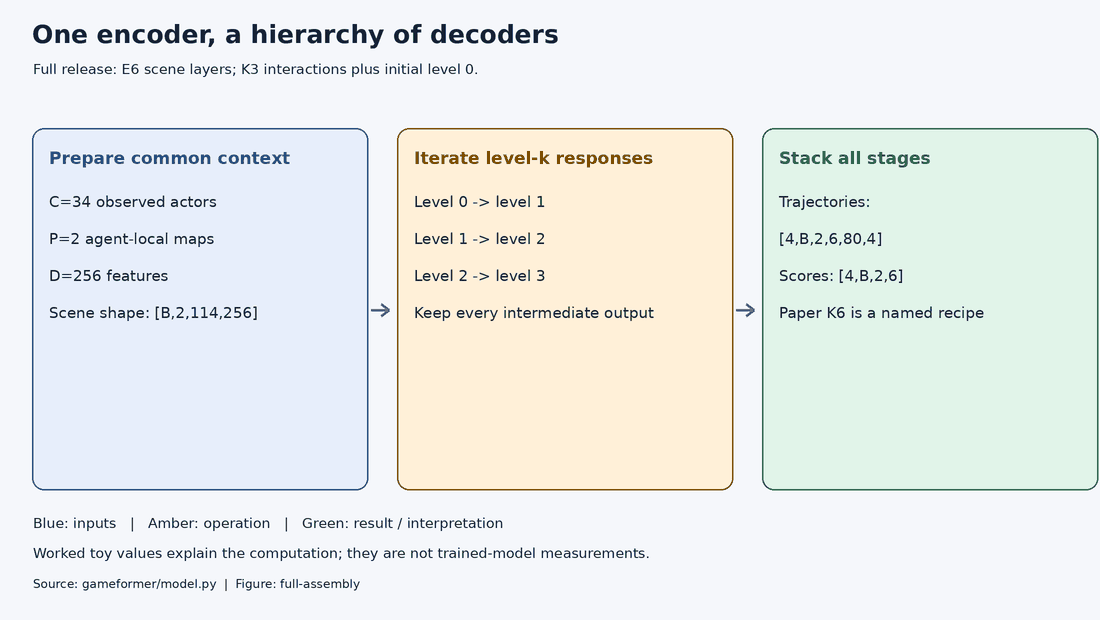

*Full release: E6 scene layers; K3 interactions plus initial level 0.*

In [ ]:
class GameFormer(nn.Module):
    def __init__(self, config: ModelConfig):
        super().__init__()
        self.config = c = config
        self.ego_encoder, self.agent_encoder = AgentEncoder(c.width), AgentEncoder(c.width)
        self.lane_encoder, self.crosswalk_encoder = LaneEncoder(c), CrosswalkEncoder(c.width)
        layer = nn.TransformerEncoderLayer(
            c.width, c.heads, c.width * 4, c.dropout, activation=F.gelu, batch_first=True
        )
        self.scene_encoder = nn.TransformerEncoder(
            layer, c.encoder_layers, enable_nested_tensor=False
        )
        self.mode_embedding = nn.Embedding(c.modes, c.width)
        self.agent_embedding = nn.Embedding(c.predicted, c.width)
        self.initial_cross, self.initial_head = AttentionBlock(c), GaussianHead(c)
        self.future_encoder = FutureEncoder(c)
        self.interactions = nn.ModuleList([InteractionDecoder(c) for _ in range(c.levels)])

    def forward(self, batch: dict[str, Tensor]) -> dict[str, Tensor]:
        c = self.config
        actors = torch.cat((batch["ego_state"][:, None], batch["neighbors_state"]), 1)
        actors = torch.where(batch["actor_valid"][..., None], actors, 0)
        b = actors.shape[0]
        actor_mask = ~batch["actor_valid"][..., -1]
        if actor_mask[:, 0].any():
            raise ValueError("Focal actor must be present")
        encoded_ego = self.ego_encoder(actors[:, 0])[:, None]
        if c.actors > 1:
            others = self.agent_encoder(actors[:, 1:].reshape(-1, c.history, 9)).reshape(
                b, c.actors - 1, c.width
            )
            encoded_actors = torch.cat((encoded_ego, others), 1)
        else:
            encoded_actors = encoded_ego
        lanes = torch.where(batch["lane_valid"][..., None], batch["map_lanes"], 0)
        crosswalks = torch.where(batch["crosswalk_valid"][..., None], batch["map_crosswalks"], 0)
        lane_features = self.lane_encoder(lanes).reshape(
            b * c.predicted, c.lanes, c.lane_points, c.width
        )
        cw_features = self.crosswalk_encoder(crosswalks).reshape(
            b * c.predicted, c.crosswalks, c.crosswalk_points, c.width
        )
        lane_tokens, lane_mask = segment_points(
            lane_features,
            batch["lane_valid"].reshape(b * c.predicted, c.lanes, c.lane_points),
            c.lane_stride,
            c.partial_segments,
        )
        cw_tokens, cw_mask = segment_points(
            cw_features,
            batch["crosswalk_valid"].reshape(b * c.predicted, c.crosswalks, c.crosswalk_points),
            c.crosswalk_stride,
            c.partial_segments,
        )
        scene = torch.cat(
            (
                encoded_actors[:, None]
                .expand(-1, c.predicted, -1, -1)
                .reshape(b * c.predicted, c.actors, c.width),
                lane_tokens,
                cw_tokens,
            ),
            1,
        )
        mask = torch.cat(
            (
                actor_mask[:, None].expand(-1, c.predicted, -1).reshape(b * c.predicted, c.actors),
                lane_mask,
                cw_mask,
            ),
            1,
        )
        scene = self.scene_encoder(scene, src_key_padding_mask=mask)
        scene = scene.reshape(b, c.predicted, -1, c.width)
        mask = mask.reshape(b, c.predicted, -1)
        focal_history = scene[
            :,
            torch.arange(c.predicted, device=actors.device),
            torch.arange(c.predicted, device=actors.device),
        ]
        query = (
            focal_history[:, :, None]
            + self.mode_embedding.weight[None, None]
            + self.agent_embedding.weight[None, :, None]
        )
        content = self.initial_cross(
            query.reshape(b * c.predicted, c.modes, c.width),
            scene.reshape(b * c.predicted, -1, c.width),
            mask.reshape(b * c.predicted, -1),
        ).reshape(b, c.predicted, c.modes, c.width)
        current = actors[:, : c.predicted, -1]
        trajectories, scores = self.initial_head(content, current)
        all_trajectories, all_scores = [trajectories], [scores]
        for module in self.interactions:
            block = cast(InteractionDecoder, module)
            multi = self.future_encoder(trajectories[..., :2], current)
            weighted = multi * scores.softmax(-1)[..., None]
            futures = weighted.sum(2) if c.normalized_future_pool else weighted.mean(2)
            interaction = block.interaction(futures, futures, actor_mask[:, : c.predicted])
            context = torch.cat((interaction[:, None].expand(-1, c.predicted, -1, -1), scene), 2)
            future_mask = actor_mask[:, None, : c.predicted].expand(-1, c.predicted, -1).clone()
            future_mask |= torch.eye(c.predicted, device=actors.device, dtype=torch.bool)[None]
            combined_mask = torch.cat((future_mask, mask), 2)
            content = block.cross(
                (content + multi).reshape(b * c.predicted, c.modes, c.width),
                context.reshape(b * c.predicted, -1, c.width),
                combined_mask.reshape(b * c.predicted, -1),
            ).reshape(b, c.predicted, c.modes, c.width)
            trajectories, scores = block.head(content, current)
            all_trajectories.append(trajectories)
            all_scores.append(scores)
        return {"trajectories": torch.stack(all_trajectories), "scores": torch.stack(all_scores)}

In [ ]:
model = GameFormer(config)
outputs = model(batch)
assert outputs["trajectories"].shape == (2, 2, 2, 6, 80, 4)
print("Parameters:", sum(p.numel() for p in model.parameters()))

## Actual training objectives

Select one shared joint mode by its displacement errors. For the joint predictor, use the temporal mean and 3/5/8-second horizons. The diagonal NLL is $log\sigma_x+log\sigma_y+\frac12[(d_x/\sigma_x)^2+(d_y/\sigma_y)^2]$. The printed Eq. 3 repeats x; the correct y term agrees with the released code. Add twice the joint score cross-entropy with label smoothing .2. Sum all levels. Missing labels contribute neither error nor denominator.

Planning uses its released imitation reduction and adds .1 times the cross-level potential at levels k≥1. The potential is 1/(distance+1) below 3 m. It compares ego to previous neighbors, and neighbors to previous other neighbors, matching the released directional objective. The supplement intentionally omits this penalty for joint prediction.

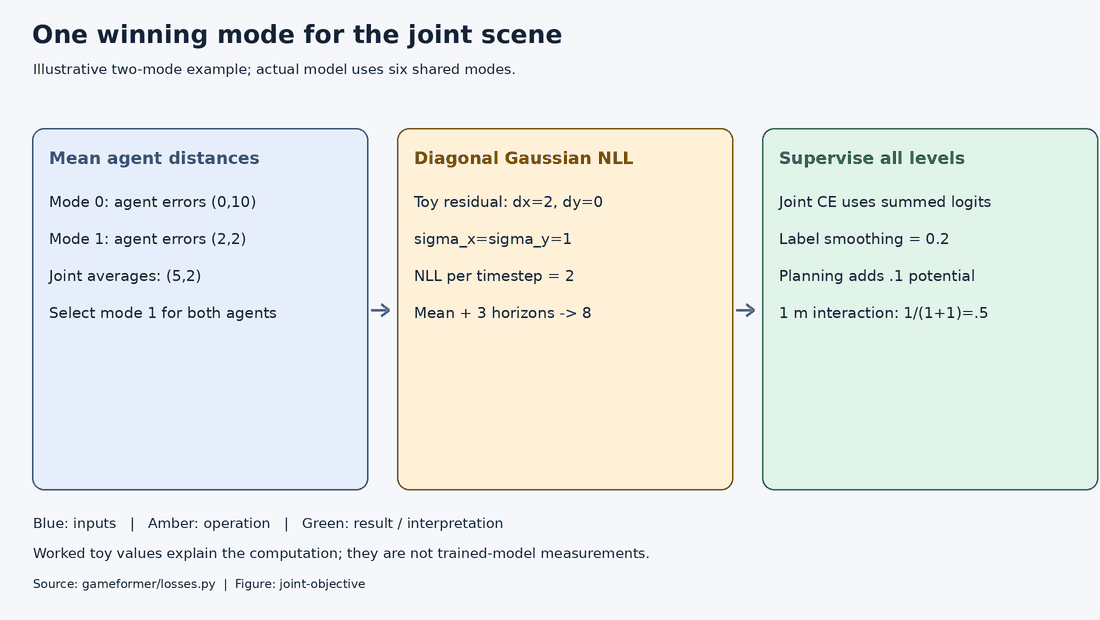

*Illustrative two-mode example; actual model uses six shared modes.*

In [ ]:
def masked_mean(value: Tensor, valid: Tensor) -> Tensor:
    return torch.where(valid, value, 0).sum() / valid.sum().clamp_min(1)


def interaction_potential(current: Tensor, previous: Tensor, valid: Tensor) -> Tensor:
    """B,P,M,T,2. Ego->previous neighbors; neighbors->previous other neighbors."""
    b, n, m, t, _ = current.shape
    if n < 2:
        return current.sum() * 0
    prev = previous[:, 1:].permute(0, 3, 1, 2, 4).reshape(b * t, (n - 1) * m, 2)
    others_valid = (
        valid[:, 1:].permute(0, 2, 1)[..., None].expand(-1, -1, -1, m).reshape(b * t, (n - 1) * m)
    )
    ego = current[:, 0].permute(0, 2, 1, 3).reshape(b * t, m, 2)
    distance = torch.cdist(ego, prev).masked_fill(~others_valid[:, None], 1000).amin(-1)
    ego_valid = valid[:, 0].reshape(b * t, 1)
    potential = torch.where((distance < 3) & ego_valid, 1 / (distance + 1), 0)
    ego_loss = potential.reshape(b, t, m).sum((1, 2)).mean()
    neighbors = current[:, 1:].permute(0, 3, 1, 2, 4).reshape(b * t, (n - 1) * m, 2)
    distance = torch.cdist(neighbors, prev)
    same_agent = (
        torch.eye(n - 1, dtype=torch.bool, device=current.device)
        .repeat_interleave(m, 0)
        .repeat_interleave(m, 1)
    )
    pair_mask = (~others_valid[:, None]) | same_agent[None]
    distance = distance.masked_fill(pair_mask, 1000).amin(-1)
    potential = torch.where((distance < 3) & others_valid, 1 / (distance + 1), 0)
    # Match source's time sum and mean across current neighbor-mode entries.
    denominator = valid[:, 1:].any(-1).sum(-1).clamp_min(1) * m
    neighbor_loss = (potential.reshape(b, t, -1).sum((1, 2)) / denominator).mean()
    return ego_loss + neighbor_loss


def objective(outputs: dict[str, Tensor], batch: dict[str, Tensor], task: str) -> dict[str, Tensor]:
    if task not in ("joint", "planning"):
        raise ValueError("task must be joint or planning")
    valid = batch["future_valid"]
    target = torch.where(valid[..., None], batch["future"].float(), 0)
    stages = outputs["trajectories"].float()
    logits = outputs["scores"].float()
    valid_agents = valid.any(-1)
    valid_scenes = valid_agents.any(-1)
    zero = stages.sum() * 0 + logits.sum() * 0
    regression, classification, interaction = zero, zero, zero
    for level, raw in enumerate(stages):
        clean = torch.where(valid[:, :, None, :, None], raw, 0)
        distance = (clean[..., :2] - target[:, :, None]).norm(dim=-1)
        if task == "joint":
            if target.shape[1:3] != (2, 80):
                raise ValueError("Joint objective requires two agents and 80 future samples")
            temporal = (distance * valid[:, :, None]).sum(-1) / valid.sum(-1)[:, :, None].clamp_min(
                1
            )
            horizons = torch.tensor([29, 49, 79], device=target.device)
            temporal = temporal + (distance[..., horizons] * valid[:, :, None, horizons]).sum(-1)
        else:
            sampled = valid[..., 4::5]
            temporal = (distance[..., 4::5] * sampled[:, :, None]).sum(-1) / sampled.sum(-1)[
                :, :, None
            ].clamp_min(1)
        joint_distance = (temporal * valid_agents[..., None]).sum(1) / valid_agents.sum(1)[
            :, None
        ].clamp_min(1)
        mode = joint_distance.argmin(-1)
        b, p, _, t, _ = raw.shape
        chosen = clean.gather(2, mode[:, None, None, None, None].expand(b, p, 1, t, 4)).squeeze(2)
        dx = target - chosen[..., :2]
        lo, hi = (0, 5) if task == "joint" else (-2, 2)
        log_std = chosen[..., 2:].clamp(lo, hi)
        nll = log_std.sum(-1) + 0.5 * (dx * torch.exp(-log_std)).square().sum(-1)
        nll = torch.where(valid, nll, 0)
        if task == "joint":
            per_agent = nll.sum(-1) / valid.sum(-1).clamp_min(1) + nll[..., horizons].sum(-1)
            regression = regression + masked_mean(per_agent, valid_agents)
            scene_logits = (logits[level] * valid_agents[..., None]).sum(1)
            ce = F.cross_entropy(scene_logits, mode, label_smoothing=0.2, reduction="none")
            classification = classification + 2 * masked_mean(ce, valid_scenes)
        else:
            regression = regression + masked_mean(nll, valid) + masked_mean(nll[:, 0], valid[:, 0])
            ce = F.cross_entropy(
                logits[level].transpose(1, 2),
                mode[:, None].expand(-1, p),
                label_smoothing=0.2,
                reduction="none",
            )
            classification = classification + masked_mean(ce, valid_agents)
            if level:
                interaction = interaction + 0.1 * interaction_potential(
                    clean[..., :2],
                    torch.where(valid[:, :, None, :, None], stages[level - 1, ..., :2], 0),
                    valid,
                )
    return {
        "loss": regression + classification + interaction,
        "regression": regression,
        "classification": classification,
        "interaction": interaction,
    }

In [ ]:
components = objective(outputs, batch, "joint")
assert torch.isfinite(components["loss"])
print({name: float(value.detach()) for name, value in components.items()})

## Backward and one real optimizer update

Losses are computed in FP32. The following cell performs the actual objective, backward pass, gradient clipping and AdamW update. Optimizer state and randomness must later be saved for faithful recovery. The teaching example uses one CPU batch; the trainer also supports sample-weighted accumulation and mixed precision.

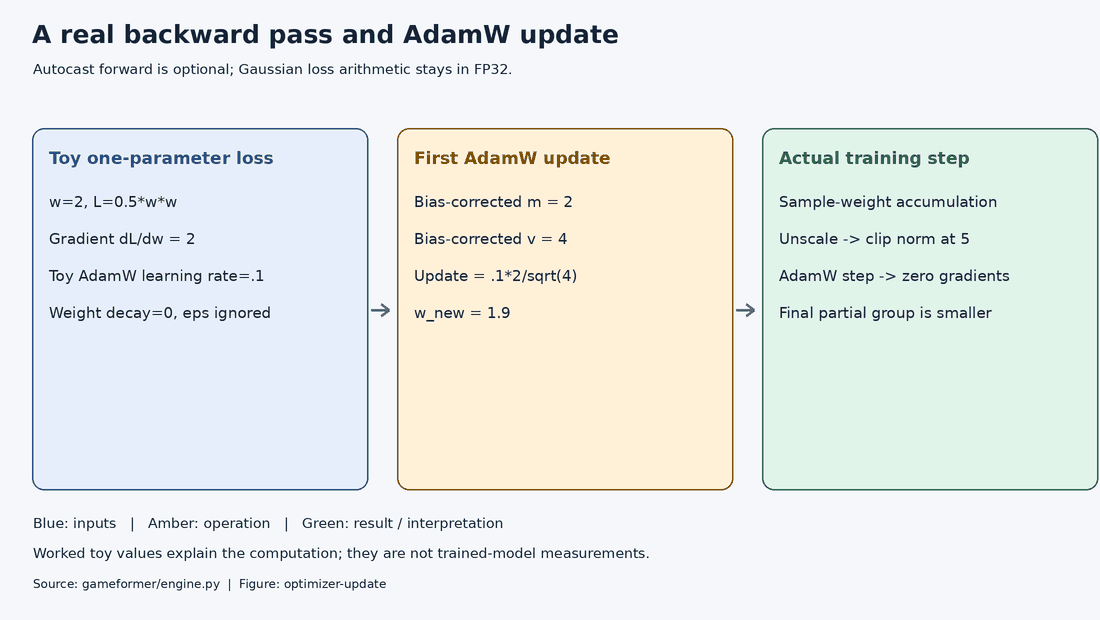

*Autocast forward is optional; Gaussian loss arithmetic stays in FP32.*

In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
optimizer.zero_grad(set_to_none=True)
loss = objective(model(batch), batch, "joint")["loss"]
loss.backward()
gradient_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0, error_if_nonfinite=True)
optimizer.step()
assert torch.isfinite(gradient_norm)
print("Gradient norm:", float(gradient_norm))

## Decode and measure

Sum agent logits, softmax over modes, and select the same highest-score mode for every agent. Diagnostic ADE is average valid displacement; FDE uses each agent’s last valid step. Official WOMD metrics require the SDK, actual labels and the prescribed split. The adapter below requires full labeled states and explicit validity; it cannot produce official results merely by renaming a diagnostic.

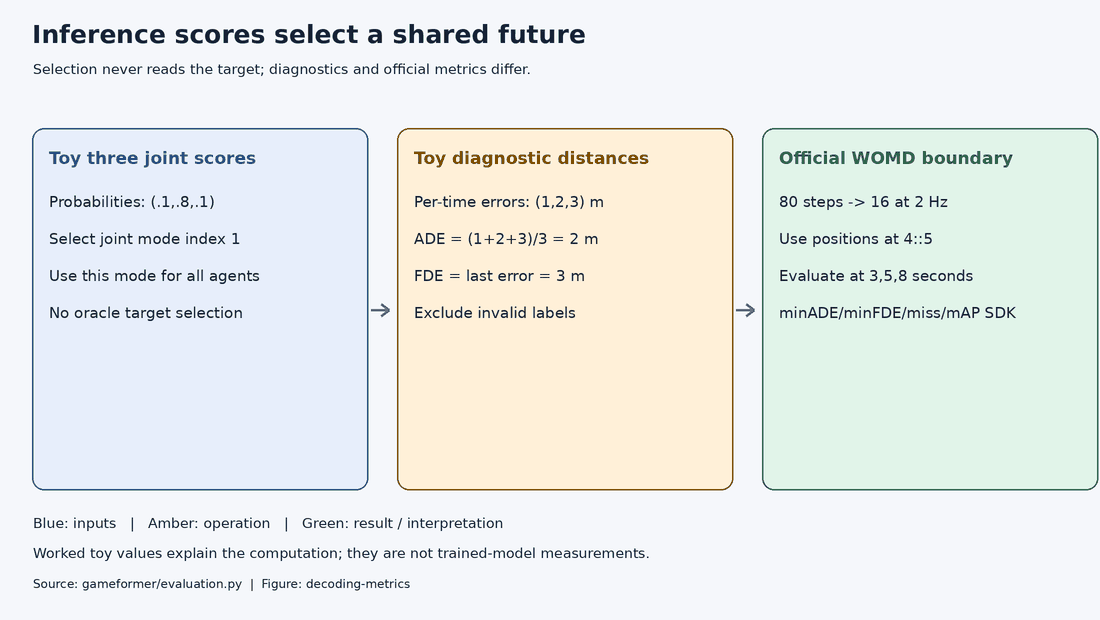

*Selection never reads the target; diagnostics and official metrics differ.*

In [ ]:
def decode(outputs: dict[str, Tensor], task: str = "joint") -> tuple[Tensor, Tensor]:
    trajectories, scores = outputs["trajectories"][-1], outputs["scores"][-1]
    b, p, _, t, _ = trajectories.shape
    if task == "joint":
        probabilities = scores.sum(1).softmax(-1)
        mode = probabilities.argmax(-1)[:, None].expand(-1, p)
    elif task == "planning":
        probabilities = scores.softmax(-1)
        mode = probabilities.argmax(-1)
    else:
        raise ValueError("task must be joint or planning")
    selected = trajectories.gather(2, mode[:, :, None, None, None].expand(b, p, 1, t, 4)).squeeze(2)
    return selected[..., :2], probabilities


def diagnostic_totals(
    outputs: dict[str, Tensor], batch: dict[str, Tensor], task: str = "joint"
) -> dict[str, float]:
    prediction, _ = decode(outputs, task)
    valid = batch["future_valid"]
    target = torch.where(valid[..., None], batch["future"], 0)
    distance = (prediction.float() - target).norm(dim=-1)
    steps = torch.arange(valid.shape[-1], device=valid.device)
    last = torch.where(valid, steps, -1).amax(-1)
    present = last >= 0
    final = distance.gather(-1, last.clamp_min(0)[..., None]).squeeze(-1)
    return {
        "distance_sum": float(torch.where(valid, distance, 0).sum()),
        "valid_steps": float(valid.sum()),
        "final_distance_sum": float(torch.where(present, final, 0).sum()),
        "valid_agents": float(present.sum()),
    }


def official_metric_inputs(
    outputs: dict[str, Tensor], batch: dict[str, Tensor]
) -> dict[str, Tensor]:
    """WOMD joint layout: B,1,M,2,16,2; actual labeled state/validity required."""
    future = batch["future_state"]
    if future.shape[1:3] != (2, 80):
        raise ValueError("Official joint metrics require two agents and 80 future steps")
    actors = torch.cat((batch["ego_state"][:, None], batch["neighbors_state"]), 1)[:, :2]
    all_state = torch.cat((actors[..., :5], future), 2)
    sizes = actors[:, :, -1, 5:7][:, :, None].expand(-1, -1, all_state.shape[2], -1)
    gt = torch.cat((all_state[..., :2], sizes, all_state[..., 2:]), -1)
    probabilities = outputs["scores"][-1].sum(1).softmax(-1)
    b = future.shape[0]
    return {
        "prediction_trajectory": outputs["trajectories"][-1, ..., 4::5, :2].permute(0, 2, 1, 3, 4)[
            :, None
        ],
        "prediction_score": probabilities[:, None],
        "ground_truth_trajectory": gt,
        "ground_truth_is_valid": torch.cat(
            (batch["actor_valid"][:, :2], batch["future_valid"]), -1
        ),
        "object_type": actors[:, :, -1, 8].long(),
        "prediction_ground_truth_indices": torch.arange(2, device=future.device)[None, None].expand(
            b, 1, -1
        ),
        "prediction_ground_truth_indices_mask": batch["future_valid"].any(-1)[:, None],
    }


def official_metrics(inputs: dict[str, Tensor]) -> dict[str, float]:
    try:
        import tensorflow as tf
        from google.protobuf import text_format
        from waymo_open_dataset.metrics.ops import py_metrics_ops
        from waymo_open_dataset.metrics.python import config_util_py
        from waymo_open_dataset.protos import motion_metrics_pb2
    except ImportError as error:
        raise RuntimeError(
            "Official evaluation requires the compatible Waymo/TensorFlow SDK; see docs/data.md"
        ) from error
    config = motion_metrics_pb2.MotionMetricsConfig()
    text_format.Parse(
        """track_steps_per_second:10 prediction_steps_per_second:2
    track_history_samples:10 track_future_samples:80 speed_lower_bound:1.4
    speed_upper_bound:11.0 speed_scale_lower:0.5 speed_scale_upper:1.0
    step_configurations {measurement_step:5 lateral_miss_threshold:1.0 longitudinal_miss_threshold:2.0}
    step_configurations {measurement_step:9 lateral_miss_threshold:1.8 longitudinal_miss_threshold:3.6}
    step_configurations {measurement_step:15 lateral_miss_threshold:3.0 longitudinal_miss_threshold:6.0}
    max_predictions:6""",
        config,
    )
    values = py_metrics_ops.motion_metrics(
        config=config.SerializeToString(),
        **{
            name: tf.convert_to_tensor(value.detach().cpu().numpy())
            for name, value in inputs.items()
        },
    )
    breakdowns = config_util_py.get_breakdown_names_from_motion_config(config)
    return {
        f"official/{metric}/{name}": float(values[i][j].numpy())
        for i, metric in enumerate(("minADE", "minFDE", "miss_rate", "overlap_rate", "mAP"))
        for j, name in enumerate(breakdowns)
    }

In [ ]:
model.eval()
with torch.no_grad():
    inference = model(batch)
selected, probabilities = decode(inference)
print("Selected xy:", selected.shape)
print(diagnostic_totals(inference, batch))
sdk_layout = official_metric_inputs(inference, batch)
assert sdk_layout["prediction_trajectory"].shape == (2, 1, 6, 2, 16, 2)
fig, ax = plt.subplots(figsize=(6, 3))
for agent in range(2):
    truth = batch["future"][0, agent]
    path = selected[0, agent]
    ax.plot(truth[:, 0], truth[:, 1], "--", label=f"target {agent}")
    ax.plot(path[:, 0], path[:, 1], label=f"random-model prediction {agent}")
ax.set(xlabel="local x (m)", ylabel="local y (m)", title="Synthetic diagnostic after one update")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()
plt.close(fig)

## Optional real data and recovery

Infrastructure is separate from the model. `gameformer.engine` provides data loading, atomic epoch-boundary checkpoints and tracking. These imports are deliberately opt-in; the architecture above needs no package import. Read the data guide for practical-preprocessing differences. Explicit real mode fails if assets are missing. A full training run requires a dataset, hardware preflight and an authorized budget. Schema-2 checkpoints keep the sampler independent of worker startup and reject changed cache manifests before restoring state. Original config/environment records remain intact; `sessions/` stores every restart. Exact recovery covers deterministic datasets without random worker augmentation.

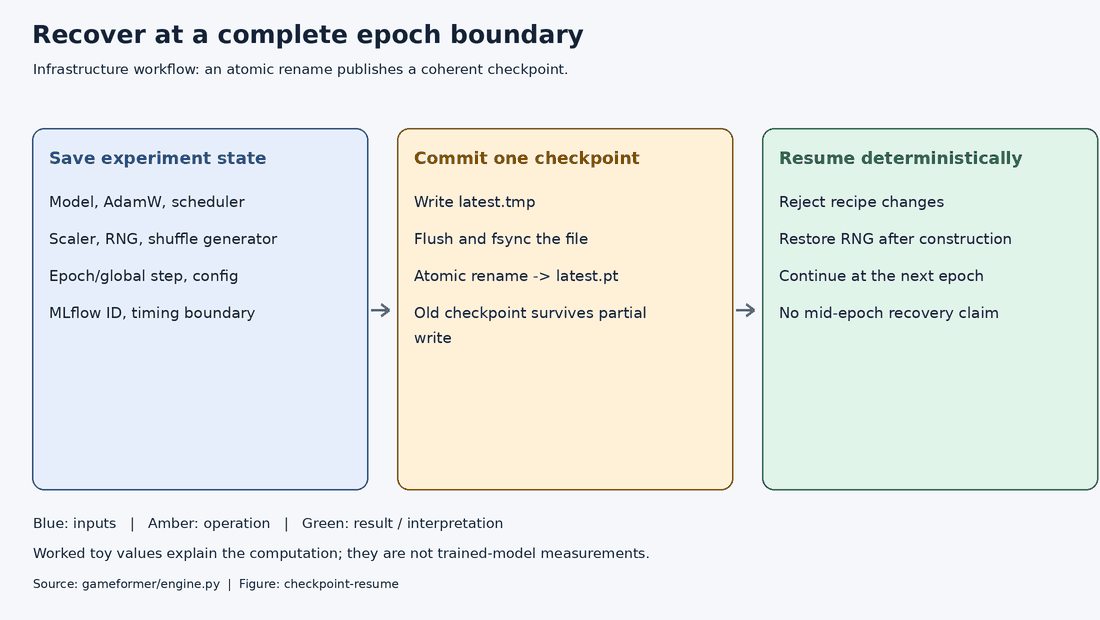

*Infrastructure workflow: an atomic rename publishes a coherent checkpoint.*

In [ ]:
RUN_REAL = False
if RUN_REAL:
    from pathlib import Path

    from gameformer.config import RunConfig
    from gameformer.engine import train

    real_config = RunConfig.load("configs/practical_joint.json")
    if not real_config.train_data or not Path(real_config.train_data).is_dir():
        raise FileNotFoundError("Set train_data and validation_data to genuine prepared caches")
    train(real_config, "outputs/real-run")

## Tracking and trustworthy remaining time

MLflow is optional and logs the experiment’s source/config/data identity, loss components, gradient norms, trajectories and progress. After resume, measure the current session’s rate and estimate only remaining work. Include observed validation and checkpoint overhead; report active time separately from wall time and downtime. Estimates before two completed epochs are provisional. `progress.json` works with tracking disabled.

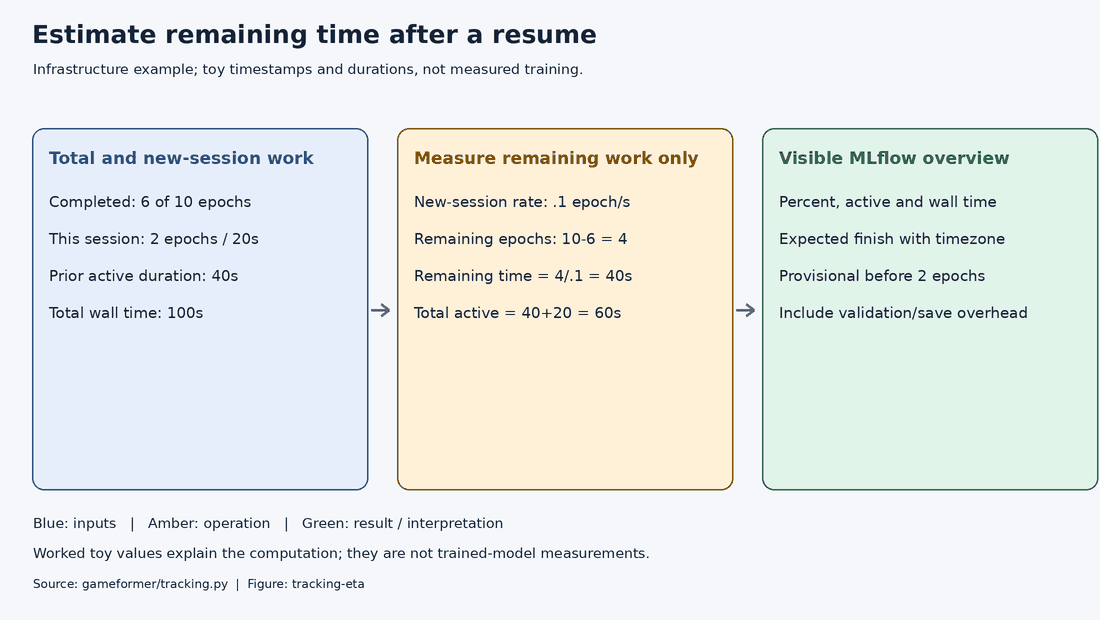

*Infrastructure example; toy timestamps and durations, not measured training.*

In [ ]:
completed, total = 6, 10
session_epochs, session_seconds = 2, 20
remaining_seconds = (total - completed) / (session_epochs / session_seconds)
assert remaining_seconds == 40
print("Toy remaining duration:", remaining_seconds, "seconds")

## What this execution establishes

The model, actual objectives and optimizer update execute on seeded synthetic CPU data. It establishes no paper metric, real-data parity or closed-loop planning score. The release omits the 64-mode EM ensemble and closed-loop WOMD code; nuPlan adds a distinct planning framework. The source audit records these boundaries and the corrected validity behavior. Refer to `COMMAND_GUIDE.md` for training, resume, local MLflow, loader/step/end-to-end benchmarks and bounded tuning.